# psfcal — what do the options do?

`quickstart.ipynb` shows *how to call* each function. This notebook shows **what the main options change**.

Everything runs on a synthetic chunk where we **know the true PSF**, so every option can be judged against the truth:

> **PSF error** = RMS difference between the reconstructed and the true PSF, as a % of the true PSF's RMS (lower is better).

Contents

1. The synthetic test chunk
2. Baseline: default settings
3. How much data do you need? (`n_chunks` / chunk size, S/N)
4. Background: `subtract_background`
5. Outliers: `sigma_clip_nsigma`, `student_t_dof`
6. Iterations and the secondary GP: `n_iterations`, `use_secondary_gp`
7. Deconvolution: `rl_iters`, `l2_damp`
8. Cube geometry: `n_chunks`, `chunk_margin_pix`
9. Cheat sheet

> **Run time.** One GP fit takes tens of seconds, so results are cached in `parameters_cache.pkl` next to this notebook and the notebook opens instantly.
> Set `RECOMPUTE = True` below to redo everything (~15 min).

In [1]:
import pickle, time, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import psfcal

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

RECOMPUTE = False                      # True = ignore the cache and refit everything
CACHE = Path("parameters_cache.pkl")
cache = {} if (RECOMPUTE or not CACHE.exists()) else pickle.load(open(CACHE, "rb"))

## 1. The synthetic test chunk

A comb of emission lines (think LFC), each smeared by the **same asymmetric instrumental profile** (a narrow core plus a broad shoulder, so it is *not* a Gaussian).
The helper `make_chunk` lets us switch on difficulties one at a time: a sloped background, cosmic rays, fewer lines, lower S/N.

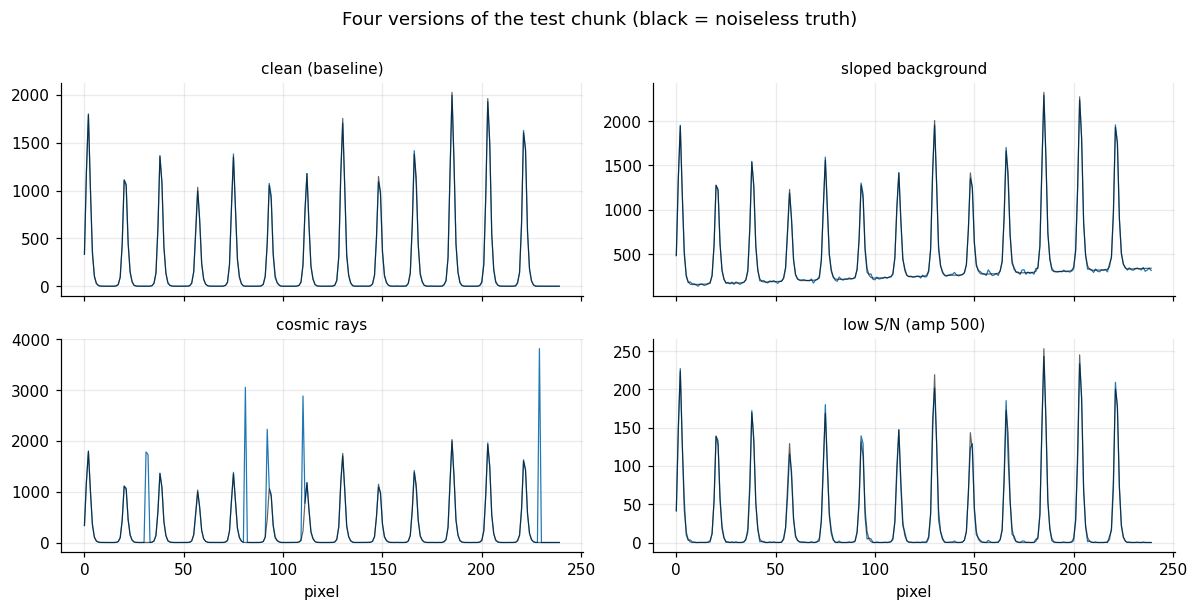

In [2]:
def make_kernel():
    dx = np.linspace(-8, 8, 4000)
    y = np.exp(-0.5 * (dx / 0.9) ** 2) + 0.35 * np.exp(-0.5 * ((dx - 0.4) / 1.6) ** 2)
    y /= np.trapz(y, dx)
    dx = dx - np.trapz(dx * y, dx)          # centroid at 0
    return dx, y / np.trapz(y, dx)

KX, KY = make_kernel()                      # the TRUE PSF

def make_chunk(seed=1, n_pix=240, spacing=18.3, amp=4000.0, bkg=(0.0, 0.0), n_cr=0):
    # returns x, y, y_err, y_noiseless. bkg = (offset, slope per pixel); n_cr = number of cosmic rays
    rng = np.random.default_rng(seed)
    x = np.arange(n_pix, dtype=float)
    c = np.arange(2, n_pix - 2, spacing)
    c = c + rng.uniform(-0.3, 0.3, len(c))
    a = amp * rng.uniform(0.6, 1.4, len(c))
    y0 = bkg[0] + bkg[1] * x
    for ci, ai in zip(c, a):
        y0 = y0 + ai * np.interp(x - ci, KX, KY, left=0, right=0)
    err = np.sqrt(y0 + 1.0)
    y = np.clip(y0 + rng.normal(0, err), 0, None)
    for p in rng.choice(n_pix, n_cr, replace=False):
        y[p] += rng.uniform(1500, 4000)     # cosmic ray
    return x, y, err, y0

def psf_error(psf_x, psf_mean):
    t = np.interp(psf_x, KX, KY, left=0, right=0)
    return 100 * np.sqrt(np.trapz((psf_mean - t) ** 2, psf_x) / np.trapz(t ** 2, psf_x))

fig, axs = plt.subplots(2, 2, figsize=(11, 5.5), sharex=True)
for ax, (title, kw) in zip(axs.flat, [
        ("clean (baseline)", {}),
        ("sloped background", dict(bkg=(150.0, 0.8))),
        ("cosmic rays", dict(n_cr=6)),
        ("low S/N (amp 500)", dict(amp=500.0))]):
    x, y, e, y0 = make_chunk(**kw)
    ax.plot(x, y, lw=0.8); ax.plot(x, y0, lw=0.8, c="k", alpha=0.6)
    ax.set_title(title, fontsize=10)
for ax in axs[1]: ax.set_xlabel("pixel")
fig.suptitle("Four versions of the test chunk (black = noiseless truth)", y=1.0)
plt.tight_layout(); plt.show()

## 2. Baseline: default settings

`fit()` runs `compute_psf_chunk_pixel` once and caches what we need.
The plotting helper `compare()` draws, for a set of runs:

* **left**: the reconstructed PSFs on top of the true one (thick grey),
* **right**: reconstructed − true (a perfect run is a flat line at 0),
* the legend gives the PSF error and the run time.

12 lines stacked, 231 stacked points


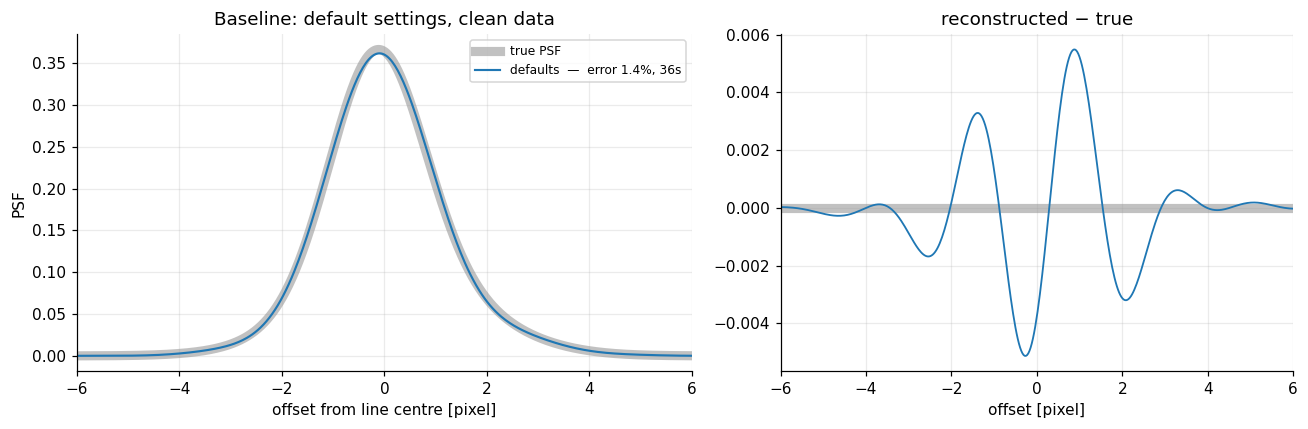

In [3]:
def fit(key, data, **kw):
    # Run compute_psf_chunk_pixel(*data, **kw) once; cache the result under `key`.
    if key not in cache:
        x, y, e = data[:3]
        t0 = time.time()
        r = psfcal.compute_psf_chunk_pixel(x, y, e, **kw)
        cache[key] = dict(psf_x=r["psf_x"], psf_mean=r["psf_mean"], psf_std=r["psf_std"],
                          n_lines=len(r["line_centres"]), seconds=time.time() - t0,
                          stacked_x=r["stacked_x"], stacked_y=r["stacked_y"])
        pickle.dump(cache, open(CACHE, "wb"))
    r = cache[key]
    r["error"] = psf_error(r["psf_x"], r["psf_mean"])
    return r

def compare(runs, labels, title, xlim=(-6, 6), colors=None):
    # runs: list of fit() results.  Left: PSFs vs truth.  Right: residuals vs truth.
    colors = colors or plt.rcParams["axes.prop_cycle"].by_key()["color"]
    fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw=dict(width_ratios=[1.2, 1]))
    a.plot(KX, KY, c="0.6", lw=6, alpha=0.6, label="true PSF")
    b.axhline(0, c="0.6", lw=6, alpha=0.6)
    for r, lab, col in zip(runs, labels, colors):
        lab = f"{lab}  —  error {r['error']:.1f}%, {r['seconds']:.0f}s"
        a.plot(r["psf_x"], r["psf_mean"], c=col, lw=1.4, label=lab)
        b.plot(r["psf_x"], r["psf_mean"] - np.interp(r["psf_x"], KX, KY, left=0, right=0), c=col, lw=1.2)
    a.set(xlim=xlim, xlabel="offset from line centre [pixel]", ylabel="PSF", title=title)
    b.set(xlim=xlim, xlabel="offset [pixel]", title="reconstructed − true")
    a.legend(fontsize=8, loc="upper right")
    plt.tight_layout(); plt.show()

D_clean = make_chunk()
base = fit("base", D_clean)
print(f"{base['n_lines']} lines stacked, {len(base['stacked_x'])} stacked points")
compare([base], ["defaults"], "Baseline: default settings, clean data")

**How to read it.** The reconstruction follows the true asymmetric shape (narrow core + broad right shoulder) from only ~12 lines; the residual is a few 0.001 against a peak of 0.37.
What is left is photon noise in the stack, and it shrinks with more data (next section).
Note this chunk has **zero background**, which is what the defaults assume (see §4).

## 3. How much data do you need?

The PSF is built by **stacking every line in the chunk**, so accuracy depends on
*(number of lines) × (counts per line)*. The two levers you control:

* **chunk length** (`n_chunks` in the cube helpers; more chunks = shorter chunks = fewer lines per PSF but better time/wavelength resolution),
* **S/N of the calibration lines** (exposure time / lamp flux).

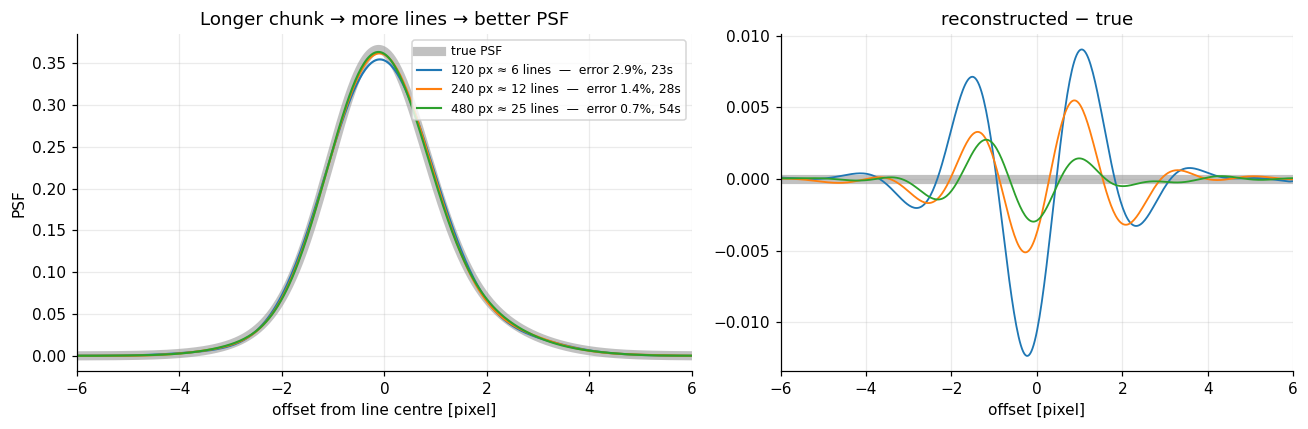

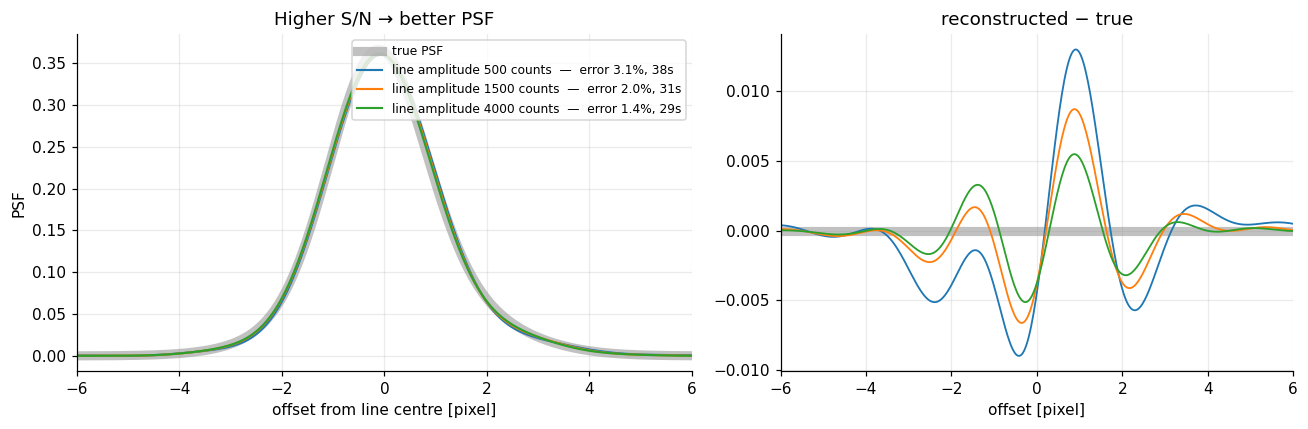

In [4]:
sizes = [120, 240, 480]
runs = [fit(f"npix{n}", make_chunk(n_pix=n)) for n in sizes]
compare(runs, [f"{n} px ≈ {r['n_lines']} lines" for n, r in zip(sizes, runs)], "Longer chunk → more lines → better PSF")

amps = [500.0, 1500.0, 4000.0]
runs = [fit(f"amp{int(a)}", make_chunk(amp=a)) for a in amps]
compare(runs, [f"line amplitude {a:.0f} counts" for a in amps], "Higher S/N → better PSF")

**Take-away.** Error roughly halves each time you double the number of lines, and falls as the line signal rises.
The catch: a longer chunk assumes the PSF is the same everywhere inside it, which is not true on a real detector, so you cannot just use one chunk per order. (This synthetic PSF is constant, so it cannot show that cost.)

## 4. Background: `subtract_background`

The method assumes the lines sit on **zero** background. If your spectrum still contains a continuum / scattered light / dark level you must either subtract it yourself, or pass `subtract_background=True` and let psfcal estimate it (low-quantile interpolation through the troughs).

> `compute_psf_chunk_pixel` defaults to `False` (assumes pre-subtracted data) but **`compute_psf_cube_pixel` defaults to `True`**.

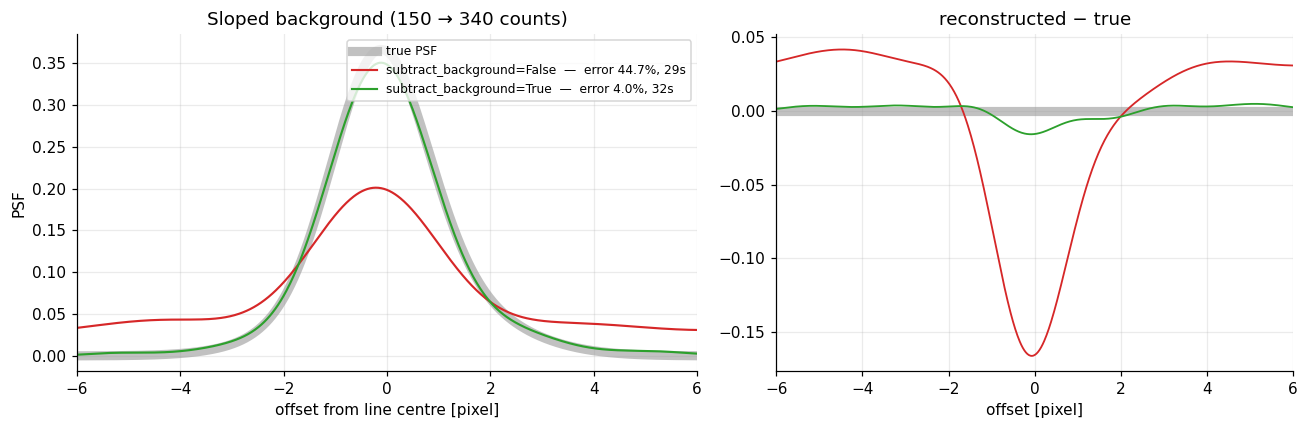

In [5]:
D_slope = make_chunk(bkg=(150.0, 0.8))
off = fit("slope_off", D_slope, subtract_background=False)
on  = fit("slope_on",  D_slope, subtract_background=True)
compare([off, on], ["subtract_background=False", "subtract_background=True"],
        "Sloped background (150 → 340 counts)", colors=["tab:red", "tab:green"])

**Take-away.** With `False` the background is read as extra line flux, which distorts the whole profile (error ~45% vs ~4%).
**If your data are not already background-subtracted, turn this on.**
(In our HARPS LFC tests, switching it off on real data was the single most damaging setting.)

## 5. Outliers: `sigma_clip_nsigma`, `student_t_dof`

Cosmic rays or faint blends add isolated bad points to the stack. Two optional (default **off**) defences:

* `sigma_clip_nsigma=k`: iterative hard clip of stacked points beyond *k* robust σ,
* `student_t_dof=ν`: soft down-weighting of large residuals (smaller ν = more aggressive).

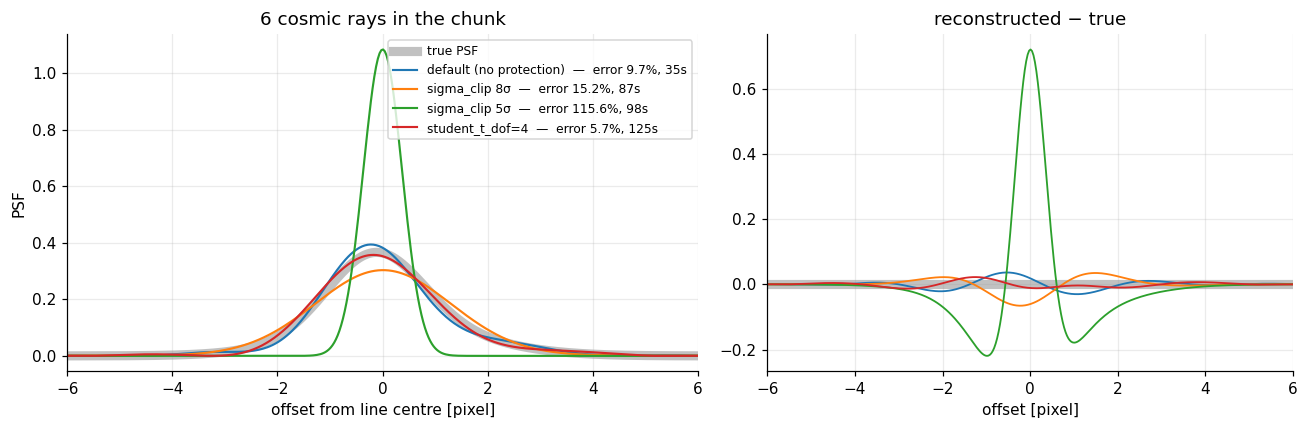

In [6]:
D_cr = make_chunk(n_cr=6)
r0 = fit("cr_default", D_cr)
r1 = fit("cr_clip8",   D_cr, sigma_clip_nsigma=8.0)
r2 = fit("cr_clip5",   D_cr, sigma_clip_nsigma=5.0)
r3 = fit("cr_t4",      D_cr, student_t_dof=4.0)
compare([r0, r1, r2, r3], ["default (no protection)", "sigma_clip 8σ", "sigma_clip 5σ", "student_t_dof=4"],
        "6 cosmic rays in the chunk")

**Take-away.** In this run `student_t_dof=4` (soft down-weighting) helped, while the hard clip **made things worse** — 8σ removed real signal and 5σ wrecked the fit (green: a spurious narrow spike). A tighter clip is not automatically better.
This is one noise realisation of a small chunk, so treat the ranking as indicative only. Always compare residuals before/after on your own data; for clean HARPS LFC data the defaults (both off) were best in our cross-validation.

## 6. Iterations and the secondary GP

* `n_iterations`: after the first PSF, re-fit every line centre/amplitude against that PSF and re-stack.
* `use_secondary_gp`: second GP that corrects the point-to-point variance empirically (§4.6 of Milaković & Jethwa 2024).

Both cost run time; do they buy accuracy?

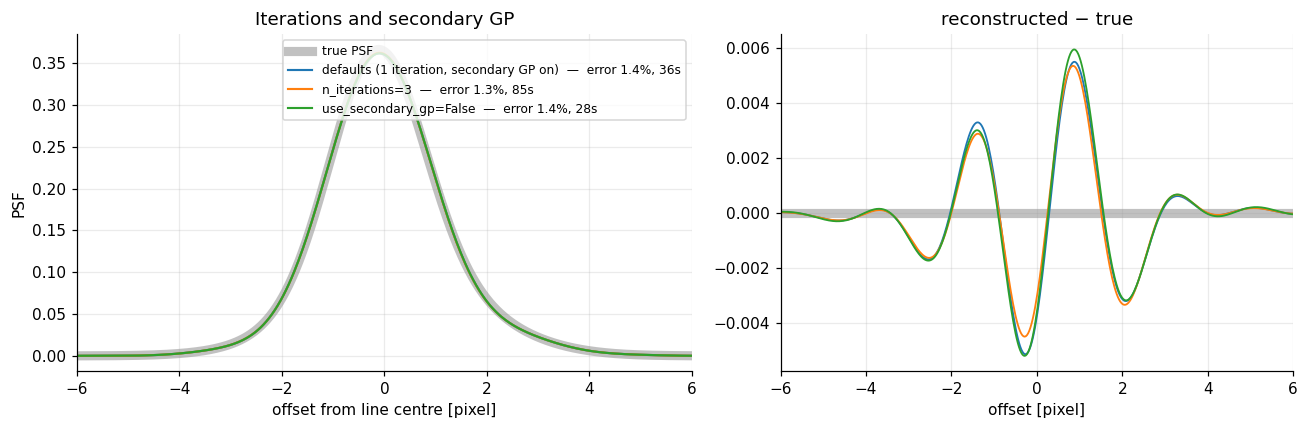

In [7]:
runs = [base,
        fit("iter3", D_clean, n_iterations=3),
        fit("nosec", D_clean, use_secondary_gp=False)]
compare(runs, ["defaults (1 iteration, secondary GP on)", "n_iterations=3", "use_secondary_gp=False"],
        "Iterations and secondary GP")

**Take-away.** The three PSFs are indistinguishable (error ~1.3–1.4%). Three iterations cost ~2–3× the time for no visible gain, and dropping the secondary GP gives the same PSF in less time (the saving grows with the number of lines; ~2× on full-size chunks in our tests).

## 7. Deconvolution: `rl_iters`, `l2_damp`

Richardson–Lucy deconvolution undoes the PSF but **amplifies noise** the longer you iterate.
We take a sharp spectrum, convolve it with the **true** PSF, add photon noise, and deconvolve with the **reconstructed** PSF from §2. Lines are faint (a few hundred counts), so noise matters.

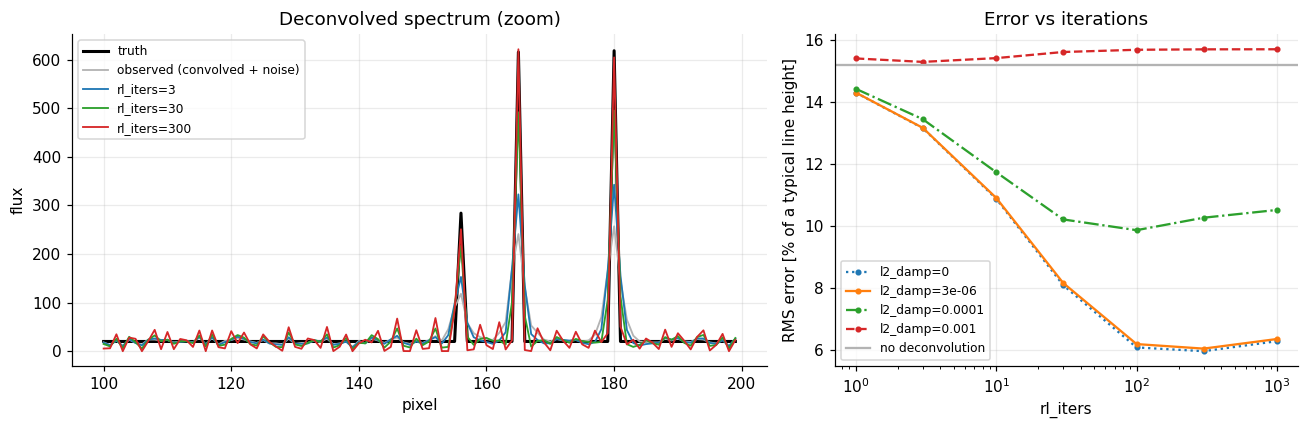

In [8]:
rng = np.random.default_rng(7)
npx = 300
xx = np.arange(npx, dtype=float)
truth = np.full(npx, 20.0)
for p in rng.choice(np.arange(15, npx - 15, 3), 12, replace=False):
    truth[p] += rng.uniform(200, 600)
obs_clean = psfcal.convolve_chunk_pixel(truth, KX, KY, pixel_radius=7)
obs = rng.poisson(np.clip(obs_clean, 0, None)).astype(float)

def deconv(**kw):
    return psfcal.deconvolve_chunk_pixel(obs, base["psf_x"], base["psf_mean"], pixel_radius=7,
                                         overlap_pix=10, continuum_normalize=False, **kw)

def rel_err(d):                          # RMS error vs truth, % of the line height
    return 100 * np.sqrt(np.mean((d - truth) ** 2)) / 400

its = [1, 3, 10, 30, 100, 300, 1000]
fig, axs = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw=dict(width_ratios=[1.5, 1]))
a, b = axs
sl = slice(100, 200)
a.plot(xx[sl], truth[sl], "k", lw=2, label="truth")
a.plot(xx[sl], obs[sl], c="0.7", lw=1.2, label="observed (convolved + noise)")
for n, col in zip([3, 30, 300], ["tab:blue", "tab:green", "tab:red"]):
    a.plot(xx[sl], deconv(rl_iters=n)[sl], c=col, lw=1.2, label=f"rl_iters={n}")
a.set(xlabel="pixel", ylabel="flux", title="Deconvolved spectrum (zoom)"); a.legend(fontsize=8)

for l2, ls in [(0.0, ":"), (3e-6, "-"), (1e-4, "-."), (1e-3, "--")]:
    b.plot(its, [rel_err(deconv(rl_iters=n, l2_damp=l2)) for n in its], ls, marker="o", ms=3, label=f"l2_damp={l2:g}")
b.axhline(rel_err(obs), c="0.7", label="no deconvolution")
b.set(xscale="log", xlabel="rl_iters", ylabel="RMS error [% of a typical line height]", title="Error vs iterations"); b.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Take-away.**
* Error falls steeply over the first ~100 iterations, bottoms out around 100–300, then creeps up as noise is amplified. The default `rl_iters=10` is conservative: safe, but far from the optimum here.
* `l2_damp` is a brake on that amplification, but a strong one (and it acts on the flux **in its own units**: the values below are for counts of a few hundred; for raw counts of ~10⁵ the same value is far stronger, so scale the flux to ~1 or keep `continuum_normalize=True`): 3e-6 (default) is almost invisible, 1e-4 stalls the sharpening, and 1e-3 is so strong that deconvolution does nothing (error stays at the observed level).
* Pick `rl_iters` from a plot like this on your own data and keep it fixed for all spectra.

## 8. Cube geometry: `n_chunks`, `chunk_margin_pix`

`compute_psf_cube_pixel/rv` splits each order into `n_chunks` equal pieces, fits each on a slice that is `chunk_margin_pix` wider on both sides (extra context so lines near a boundary are not lost), and hands the *margin-free* edges to `deconvolve_order`.

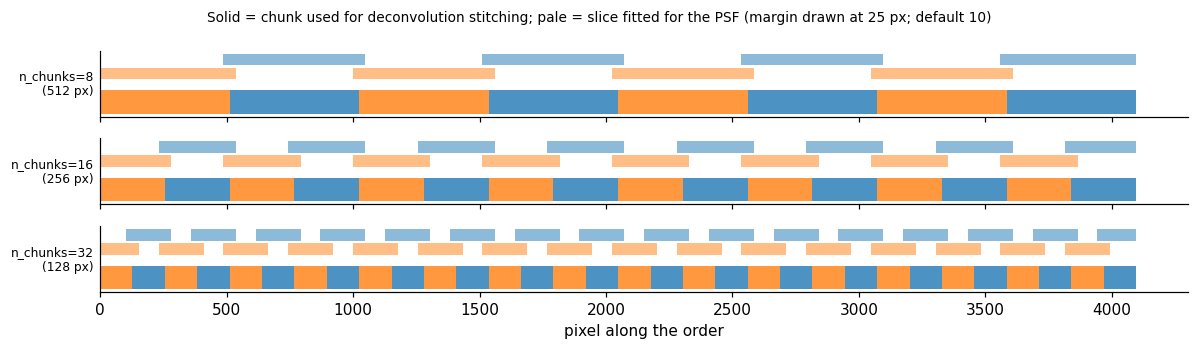

In [9]:
n_pix = 4096
fig, axs = plt.subplots(3, 1, figsize=(11, 3.2), sharex=True)
for ax, nch in zip(axs, [8, 16, 32]):
    chunks, edges = psfcal.make_chunk_edges(n_pix, nch, margin=25)    # margin exaggerated (default 10) so it is visible
    for i, ((s, e), (rs, re)) in enumerate(zip(chunks, edges)):
        col = "tab:blue" if i % 2 else "tab:orange"
        ax.barh(0, re - rs, left=rs, height=0.5, color=col, alpha=0.8)
        ax.barh(0.6 + 0.3 * (i % 2), e - s, left=s, height=0.25, color=col, alpha=0.5)
    ax.set_yticks([]); ax.set_ylabel(f"n_chunks={nch}\n({n_pix // nch} px)", rotation=0, ha="right", va="center", fontsize=8)
    ax.grid(False)
axs[-1].set_xlabel("pixel along the order")
fig.suptitle("Solid = chunk used for deconvolution stitching; pale = slice fitted for the PSF (margin drawn at 25 px; default 10)", fontsize=9)
plt.tight_layout(); plt.show()

**Rule of thumb.** Choose `n_chunks` so that each chunk contains **a few tens of calibration lines** (§3), and leave `chunk_margin_pix` at its default unless your line spacing is very large.

## 9. Cheat sheet — measured on this notebook

In [10]:
rows = [("defaults (240 px, clean)", "base"),
        ("120 px chunk", "npix120"), ("480 px chunk", "npix480"),
        ("line amplitude 500", "amp500"), ("line amplitude 1500", "amp1500"),
        ("sloped bkg, subtract_background=False", "slope_off"), ("sloped bkg, subtract_background=True", "slope_on"),
        ("cosmic rays, no protection", "cr_default"), ("cosmic rays, sigma_clip 8", "cr_clip8"),
        ("cosmic rays, sigma_clip 5", "cr_clip5"), ("cosmic rays, student_t_dof=4", "cr_t4"),
        ("n_iterations=3", "iter3"), ("use_secondary_gp=False", "nosec")]
df = pd.DataFrame([dict(setting=n, PSF_error_pct=round(fit(k, None)["error"], 1) if k in cache else np.nan,
                        seconds=round(cache[k]["seconds"]) if k in cache else np.nan,
                        n_lines=cache[k]["n_lines"] if k in cache else np.nan) for n, k in rows])
df

,setting,PSF_error_pct,seconds,n_lines
0,"defaults (240 px, clean)",1.4,36,12
1,120 px chunk,2.9,23,6
2,480 px chunk,0.7,54,25
3,line amplitude 500,3.1,38,12
4,line amplitude 1500,2.0,31,12
5,"sloped bkg, subtract_background=False",44.7,29,15
6,"sloped bkg, subtract_background=True",4.0,32,15
7,"cosmic rays, no protection",9.7,35,13
8,"cosmic rays, sigma_clip 8",15.2,87,13
9,"cosmic rays, sigma_clip 5",115.6,98,13


| Option | Default | Change it when… |
|---|---|---|
| `subtract_background` | `False` (single chunk) / `True` (cube) | the data still contain a background — **most important** |
| `n_chunks`, chunk length | 32 | too few lines per chunk (raise length) or the PSF varies along the order (shorten) |
| `n_iterations` | 1 | rarely; costs run time for little gain |
| `use_secondary_gp` | `True` | set `False` to halve the run time with nearly the same PSF |
| `sigma_clip_nsigma`, `student_t_dof` | off | real outliers (cosmics, blends) are visible in the residuals |
| `max_half_window`, `min_window_width` | 15, 6 | lines are blended or very unevenly spaced |
| `rl_iters`, `l2_damp` | 10, 3e-6 | pick `rl_iters` from an error-vs-iterations plot (§7); keep `l2_damp` small (damping ∝ flux × `l2_damp`, so scale the flux to ~1 if `continuum_normalize=False`) |
| `n_psf_points` | 800 (pixel) / 500 (RV) | only the sampling of the returned PSF |

The RV-space variants (`compute_psf_chunk_rv`, `compute_psf_cube_rv`) take the same options plus the wavelength solution and theoretical line positions; see `quickstart.ipynb`.